# cfDNA cancer detection with LEAF-1+MIL (Figure 6a-d)

Reads tables from `../data/` and writes figures to `../output/`. Source notebooks are listed in `../../NOTEBOOK_PROVENANCE.tsv`.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from this notebook's folder (nbconvert default),
# from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)


DATA: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/cfdna/data
OUT : /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/cfdna/output


saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/cfdna/output/cfdna_pan_cancer_roc.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/cfdna/output/cfdna_pan_cancer_roc.png


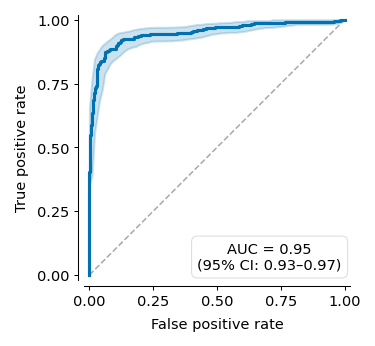

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 6,
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'lines.linewidth': 1, 'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight', 'axes.spines.top': False, 'axes.spines.right': False,
})

from sklearn.metrics import roc_auc_score, roc_curve

df = pd.read_csv(DATA / 'cfdna_mil_predictions.csv').drop_duplicates(subset=['sample_id','task'], keep='first')
df = df[~df['true_group'].isin(['Duodenal_cancer', 'Unknown'])]
df_pan = df[df['task'] == 'cancer_vs_healthy'].copy(); y_true=df_pan['label'].values; y_prob=df_pan['prob_ensemble'].values
fpr_main,tpr_main,_=roc_curve(y_true,y_prob); auc_value=roc_auc_score(y_true,y_prob)
rng=np.random.default_rng(42); fpr_grid=np.linspace(0,1,100); tpr_boot=[]; auc_boot=[]
for _ in range(1000):
    idx=rng.choice(len(y_true), size=len(y_true), replace=True); yt,yp=y_true[idx],y_prob[idx]
    if len(np.unique(yt))<2: continue
    fpr_b,tpr_b,_=roc_curve(yt,yp); auc_boot.append(roc_auc_score(yt,yp)); tpr_boot.append(np.interp(fpr_grid,fpr_b,tpr_b))
tpr_boot=np.array(tpr_boot); auc_boot=np.array(auc_boot); tpr_lower=np.percentile(tpr_boot,2.5,axis=0); tpr_upper=np.percentile(tpr_boot,97.5,axis=0); auc_ci_low=np.percentile(auc_boot,2.5); auc_ci_high=np.percentile(auc_boot,97.5)
fig,ax=plt.subplots(figsize=(2.5,2.5)); ax.fill_between(fpr_grid,tpr_lower,tpr_upper,color=OKABE_ITO['blue'],alpha=0.2,zorder=1); ax.plot([0,1],[0,1],color='#AAAAAA',linestyle='--',linewidth=0.75,zorder=1); ax.plot(fpr_main,tpr_main,color=OKABE_ITO['blue'],linewidth=1.5,zorder=3)
ax.text(0.97,0.03,f'AUC = {auc_value:.2f}\n(95% CI: {auc_ci_low:.2f}–{auc_ci_high:.2f})',transform=ax.transAxes,ha='right',va='bottom',fontsize=7,multialignment='center',bbox=dict(boxstyle='round,pad=0.4',facecolor='white',edgecolor='#DDDDDD',linewidth=0.5))
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_xlim(-0.02,1.02); ax.set_ylim(-0.02,1.02); ax.set_xticks([0,0.25,0.5,0.75,1.0]); ax.set_yticks([0,0.25,0.5,0.75,1.0]); ax.set_aspect('equal'); ax.spines['left'].set_position(('outward',3)); ax.spines['bottom'].set_position(('outward',3)); ax.tick_params(axis='both',which='both',length=2,pad=2)
plt.tight_layout(); savefig(fig, OUT, 'cfdna_pan_cancer_roc')

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/cfdna/output/cfdna_per_cancer_auc.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/cfdna/output/cfdna_per_cancer_auc.png


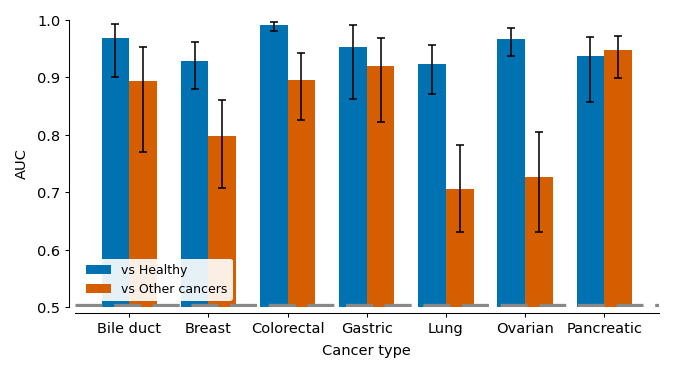

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 6,
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'lines.linewidth': 1, 'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight', 'axes.spines.top': False, 'axes.spines.right': False,
})


df_results = pd.read_csv(DATA / 'cfdna_mil_auc_all_tasks_bootstrap.csv')
cancers=['Bile_duct','Breast','Colorectal','Gastric','Lung','Ovarian','Pancreatic']; labels=['Bile duct','Breast','Colorectal','Gastric','Lung','Ovarian','Pancreatic']; x=np.arange(len(cancers)); width=0.35
auc_h=[]; err_h_low=[]; err_h_high=[]; auc_oc=[]; err_oc_low=[]; err_oc_high=[]
for cancer in cancers:
    row_h=df_results[(df_results['cancer']==cancer)&(df_results['comparison']=='vs_healthy')].iloc[0]; auc_h.append(row_h['auc']); err_h_low.append(row_h['auc']-row_h['ci_low']); err_h_high.append(row_h['ci_high']-row_h['auc'])
    row_oc=df_results[(df_results['cancer']==cancer)&(df_results['comparison']=='vs_other_cancers')].iloc[0]; auc_oc.append(row_oc['auc']); err_oc_low.append(row_oc['auc']-row_oc['ci_low']); err_oc_high.append(row_oc['ci_high']-row_oc['auc'])
fig,ax=plt.subplots(figsize=(4.5,2.5)); ax.axhline(0.5,color='#888888',linestyle='--',linewidth=3.5,zorder=3)
ax.bar(x-width/2,auc_h,width,yerr=[err_h_low,err_h_high],capsize=2,color=OKABE_ITO['blue'],label='vs Healthy',edgecolor='none',error_kw={'linewidth':0.75,'capthick':0.75},zorder=2)
ax.bar(x+width/2,auc_oc,width,yerr=[err_oc_low,err_oc_high],capsize=2,color=OKABE_ITO['orange'],label='vs Other cancers',edgecolor='none',error_kw={'linewidth':0.75,'capthick':0.75},zorder=2)
ax.set_xlabel('Cancer type'); ax.set_ylabel('AUC'); ax.set_xticks(x); ax.set_xticklabels(labels,rotation=30,ha='right'); ax.set_ylim(0.5,1.0); ax.legend(loc='lower left',frameon=True,fontsize=6,facecolor='white',edgecolor='none',framealpha=0.9); ax.spines['left'].set_position(('outward',3)); ax.spines['bottom'].set_position(('outward',3)); ax.tick_params(axis='both',which='both',length=2,pad=2)
plt.tight_layout(); savefig(fig, OUT, 'cfdna_per_cancer_auc')

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/cfdna/output/cfdna_fragment_subsampling.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/cfdna/output/cfdna_fragment_subsampling.png


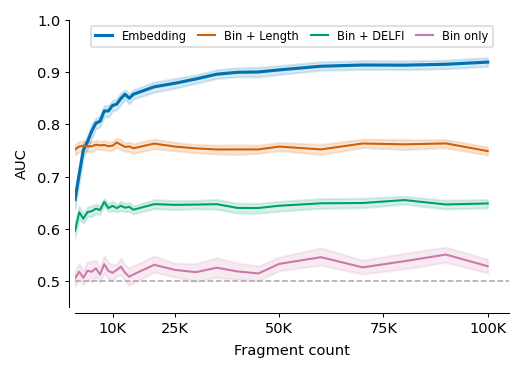

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 6,
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'lines.linewidth': 1, 'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight', 'axes.spines.top': False, 'axes.spines.right': False,
})


df_base=pd.read_csv(DATA/'cfdna_fragment_subsampling_auc.csv')
mask_task=df_base['cancer']=='cancer_vs_healthy'; mask_binning=(df_base['method']=='binning')&(df_base['n_bins']==10000.0); mask_embedding=df_base['method']=='embedding'; df_trend=df_base[mask_task & (mask_binning|mask_embedding)].copy(); df_trend=df_trend[df_trend['sample_size']>=1000].sort_values('sample_size')
COLORS={'Embedding (mod_fragment1)':'#0072B2','Binning (Bin + Length)':'#D55E00','Binning (Bin + DELFI)':'#009E73','Binning (Bin Only)':'#CC79A7'}; LABELS={'Embedding (mod_fragment1)':'Embedding','Binning (Bin + Length)':'Bin + Length','Binning (Bin + DELFI)':'Bin + DELFI','Binning (Bin Only)':'Bin only'}
fig,ax=plt.subplots(figsize=(3.5,2.5))
for config in ['Embedding (mod_fragment1)','Binning (Bin + Length)','Binning (Bin + DELFI)','Binning (Bin Only)']:
    sub=df_trend[df_trend['config']==config]
    if sub.empty: continue
    ax.fill_between(sub['sample_size'], sub['ci_low'], sub['ci_high'], color=COLORS[config], alpha=0.15); ax.plot(sub['sample_size'], sub['auc_mean'], color=COLORS[config], linewidth=1.5 if config.startswith('Embedding') else 1.0, label=LABELS[config])
ax.axhline(0.5,color='#AAAAAA',linestyle='--',linewidth=0.75,zorder=1); ax.set_xlabel('Fragment count'); ax.set_ylabel('AUC'); ax.set_xlim(1000,105000); ax.set_ylim(0.45,1.0); ax.set_xticks([10000,25000,50000,75000,100000]); ax.set_xticklabels(['10K','25K','50K','75K','100K']); ax.legend(loc='upper center',ncol=4,frameon=True,fontsize=5.5,facecolor='white',edgecolor='#DDDDDD',framealpha=0.9,columnspacing=1.0,handlelength=1.5); ax.spines['left'].set_position(('outward',3)); ax.spines['bottom'].set_position(('outward',3)); ax.tick_params(axis='both',which='both',length=2,pad=2)
plt.tight_layout(); savefig(fig, OUT, 'cfdna_fragment_subsampling')

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/cfdna/output/cfdna_fragment_efficiency.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/cfdna/output/cfdna_fragment_efficiency.png


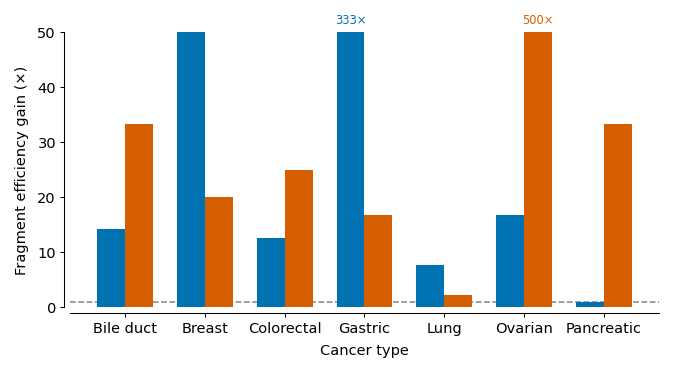

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 6,
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'lines.linewidth': 1, 'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight', 'axes.spines.top': False, 'axes.spines.right': False,
})


df_base=pd.read_csv(DATA/'cfdna_fragment_subsampling_auc.csv')
cancers=['Bile_duct','Breast','Colorectal','Gastric','Lung','Ovarian','Pancreatic']; labels=['Bile duct','Breast','Colorectal','Gastric','Lung','Ovarian','Pancreatic']
def find_fold_reduction(task, n_bins=10000.0):
    bl=df_base[(df_base['cancer']==task)&(df_base['config']=='Binning (Bin + Length)')&(df_base['n_bins']==n_bins)&(df_base['sample_size']==100000)]
    if bl.empty: return np.nan
    auc_target=bl['auc_mean'].values[0]
    emb=df_base[(df_base['cancer']==task)&(df_base['config']=='Embedding (mod_fragment1)')].sort_values('sample_size')
    match=emb[emb['auc_mean']>=auc_target]
    if match.empty: return 1.0
    return 100000/match['sample_size'].values[0]
fold_h=np.array([find_fold_reduction(f'{c}_cancer_vs_healthy') for c in cancers]); fold_oc=np.array([find_fold_reduction(f'{c}_cancer_vs_other_cancers') for c in cancers])
CAP=50; x=np.arange(len(cancers)); width=0.35
fig,ax=plt.subplots(figsize=(4.5,2.5)); ax.bar(x-width/2,np.clip(fold_h,None,CAP),width,color=OKABE_ITO['blue'],label='vs Healthy',edgecolor='none',zorder=2); ax.bar(x+width/2,np.clip(fold_oc,None,CAP),width,color=OKABE_ITO['orange'],label='vs Other cancers',edgecolor='none',zorder=2)
for i in range(len(cancers)):
    if fold_h[i]>CAP: ax.text(x[i]-width/2,CAP+1,f'{fold_h[i]:.0f}×',ha='center',va='bottom',fontsize=5.5,color=OKABE_ITO['blue'])
    if fold_oc[i]>CAP: ax.text(x[i]+width/2,CAP+1,f'{fold_oc[i]:.0f}×',ha='center',va='bottom',fontsize=5.5,color=OKABE_ITO['orange'])
ax.axhline(1,color='#888888',linestyle='--',linewidth=0.75,zorder=1); ax.set_xlabel('Cancer type'); ax.set_ylabel('Fragment efficiency gain (×)'); ax.set_xticks(x); ax.set_xticklabels(labels,rotation=30,ha='right'); ax.set_ylim(0,CAP); ax.spines['left'].set_position(('outward',3)); ax.spines['bottom'].set_position(('outward',3)); ax.tick_params(axis='both',which='both',length=2,pad=2)
plt.tight_layout(); savefig(fig, OUT, 'cfdna_fragment_efficiency')